# Yield Curve Regimes & Equity Positioning
## Week 3: Label every month with its regime

**Research question:** How have U.S. stock sectors performed in each yield-curve environment since 1976, and what does today’s environment suggest about which sectors are best positioned?

Last week you learned the four regimes. This week the notebook gives every month since 1976 one of those four labels, using a fixed rule and **only information an investor had at the end of that month**. Next week those labels get paired with sector returns.

**How to run it:** open it in [Google Colab](https://colab.research.google.com) (File → Upload notebook), then **Runtime → Run all**. It loads your dataset straight from your GitHub repository, so there’s nothing to upload.

### 1. Load your dataset
**What this does:** reads `monthly_dataset.csv` from your GitHub repository, the same file you uploaded in Week 1.

**Backups:** if a copy of the file is already in Colab’s folder, it uses that. If GitHub can’t be reached, it shows an upload button instead.

In [1]:
import io
from pathlib import Path

import pandas as pd
import requests
import matplotlib.pyplot as plt

GITHUB_CSV = "https://raw.githubusercontent.com/caden-smalls-greenwood/yield-curve-regimes/main/monthly_dataset.csv"
LOCAL_CSV  = Path("monthly_dataset.csv")
DATA = Path("data");    DATA.mkdir(exist_ok=True)
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

def load_dataset():
    if LOCAL_CSV.exists():
        print("Using the monthly_dataset.csv already in this folder.")
        return pd.read_csv(LOCAL_CSV)
    try:
        r = requests.get(GITHUB_CSV, timeout=30)
        r.raise_for_status()
        print("Loaded monthly_dataset.csv from your GitHub repository.")
        return pd.read_csv(io.StringIO(r.text))
    except requests.RequestException as e:
        print(f"Couldn't reach GitHub ({type(e).__name__}). Click 'Choose Files' and pick monthly_dataset.csv.")
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError("Put monthly_dataset.csv in this notebook's folder and run this cell again.")
        uploaded = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(uploaded.values()))))

raw = load_dataset()
data = raw.set_index(pd.PeriodIndex(raw["month"], freq="M")).drop(columns="month")
print(f"{len(data)} months, {data.index.min()} to {data.index.max()}")

Using the monthly_dataset.csv already in this folder.
605 months, 1976-06 to 2026-10


### 2. Drop the unfinished month
The newest row was downloaded partway through the month (October 18), so its yields are **mid-month**, not month-end. Every other row is a month-end value, so mixing them would break the rule you set in Week 1. The notebook drops that row.

If you ever re-download the data on the last trading day of a month, set `DROP_LAST_MONTH = False`.

In [2]:
DROP_LAST_MONTH = True

if DROP_LAST_MONTH:
    print(f"Dropping {data.index[-1]}: it was downloaded mid-month, so its yields aren't month-end values.")
    data = data.iloc[:-1]
print(f"Working sample: {data.index.min()} to {data.index.max()} ({len(data)} months)")

Dropping 2026-10: it was downloaded mid-month, so its yields aren't month-end values.
Working sample: 1976-06 to 2026-09 (604 months)


### 3. Measure how rates moved over the last 3 months
For each month, the notebook asks two questions, each comparing that month-end with the month-end **3 months earlier**:

| Question | Column | Positive means | Negative means |
|---|---|---|---|
| Did the **10-year yield** rise or fall? | `chg_10y` | Rates rising (bear) | Rates falling (bull) |
| Did the **10y–2y spread** widen or narrow? | `chg_slope` | Steepening | Flattening |

**Why 3 months?** One month is noisy, because a single surprise can flip it. A year is too slow and would miss turning points. Three months is a common middle ground. In Week 6 you’ll test whether the results hold up with other windows.

**Why this avoids look-ahead bias:** the label for, say, March 2008 uses only the March 2008 and December 2007 month-end values. An investor knew both on March 31, 2008, so nothing from the future leaks in.

`chg_2y` is shown too, so you can see which end of the curve moved more.

In [3]:
WINDOW = 3   # months

data["chg_10y"]   = (data["y10"] - data["y10"].shift(WINDOW)).round(4)
data["chg_2y"]    = (data["y2"] - data["y2"].shift(WINDOW)).round(4)
data["chg_slope"] = (data["spread_10y2y"] - data["spread_10y2y"].shift(WINDOW)).round(4)

data[["y10", "y2", "spread_10y2y", "chg_10y", "chg_2y", "chg_slope"]].tail(6)

,y10,y2,spread_10y2y,chg_10y,chg_2y,chg_slope
month,,,,,,
2026-04,4.40,3.88,0.52,0.14,0.36,-0.22
2026-05,4.45,3.98,0.47,0.48,0.60,-0.12
2026-06,4.44,4.14,0.30,0.14,0.35,-0.21
2026-07,4.75,4.28,0.47,0.35,0.40,-0.05
2026-08,4.75,4.34,0.41,0.30,0.36,-0.06
2026-09,5.29,4.88,0.41,0.85,0.74,0.11


### 4. Give every month its label
The rule, in plain English:
- **10-year fell →** "Bull." **10-year rose →** "Bear."
- **Spread widened →** "steepener." **Spread narrowed →** "flattener."

The first 3 months of the sample (June–August 1976) have no 3-month history yet, so they get no label. In the rare months where a change is exactly zero, the rule counts a flat 10-year as "Bear" and a flat spread as "flattener." That affects about 3% of months; Week 6 checks whether it matters.

In [4]:
def label(row):
    if pd.isna(row["chg_10y"]) or pd.isna(row["chg_slope"]):
        return None                                        # not enough history yet
    level = "Bull" if row["chg_10y"] < 0 else "Bear"       # yields falling = bond prices rising = bull
    slope = "steepener" if row["chg_slope"] > 0 else "flattener"
    return f"{level} {slope}"

data["regime"] = data.apply(label, axis=1)

REGIMES = ["Bull steepener", "Bear steepener", "Bull flattener", "Bear flattener"]
counts = data["regime"].value_counts().reindex(REGIMES)
print("Months in each regime:")
for name, n in counts.items():
    print(f"  {name:15s} {n:>4}   ({n / counts.sum():.0%})")
ties = int(((data["chg_10y"] == 0) | (data["chg_slope"] == 0)).sum())
print(f"\nMonths with an exactly-zero change: {ties} ({ties / counts.sum():.0%})")

Months in each regime:
  Bull steepener   133   (22%)
  Bear steepener   137   (23%)
  Bull flattener   156   (26%)
  Bear flattener   175   (29%)

Months with an exactly-zero change: 18 (3%)


### 5. Check the labels against the examples from Week 2
If the rule works, each historical example you wrote about last week should get the label you expect.

In [5]:
expected = {
    "2001-09": "Bull steepener", "2008-03": "Bull steepener", "2024-09": "Bull steepener",
    "2013-08": "Bear steepener", "2023-10": "Bear steepener",
    "2011-09": "Bull flattener", "2019-08": "Bull flattener",
    "1994-05": "Bear flattener", "2022-09": "Bear flattener",
}
check = data.loc[[pd.Period(m, "M") for m in expected], ["chg_10y", "chg_2y", "chg_slope", "regime"]].copy()
check["expected"] = list(expected.values())
check["match"] = check["regime"] == check["expected"]
print(check.to_string())
print("\nAll match:", bool(check["match"].all()))

         chg_10y  chg_2y  chg_slope          regime        expected  match
month                                                                     
2001-09    -0.82   -1.39       0.57  Bull steepener  Bull steepener   True
2008-03    -0.59   -1.43       0.84  Bull steepener  Bull steepener   True
2024-09    -0.55   -1.05       0.50  Bull steepener  Bull steepener   True
2013-08     0.62    0.09       0.53  Bear steepener  Bear steepener   True
2023-10     0.91    0.19       0.72  Bear steepener  Bear steepener   True
2011-09    -1.26   -0.20      -1.06  Bull flattener  Bull flattener   True
2019-08    -0.64   -0.45      -0.19  Bull flattener  Bull flattener   True
1994-05     1.02    1.34      -0.32  Bear flattener  Bear flattener   True
2022-09     0.85    1.30      -0.45  Bear flattener  Bear flattener   True

All match: True


### 6. How long does a regime usually last?
A "stretch" is a run of consecutive months with the same label. If stretches are short, the labels are flipping often, and that’s worth knowing before you build an investment view on them.

In [6]:
labeled = data["regime"].dropna()
stretch_id = (labeled != labeled.shift()).cumsum().rename("stretch")
stretches = labeled.groupby(stretch_id).agg(regime="first", months="size")

years = len(labeled) / 12
print(f"Regime changes: {len(stretches) - 1} over {years:.0f} years, about {(len(stretches) - 1) / years:.1f} per year")
print(f"Average stretch: {stretches['months'].mean():.1f} months. Longest: {stretches['months'].max()} months.\n")
print("Average stretch by regime (months):")
print(stretches.groupby("regime")["months"].mean().reindex(REGIMES).round(1).to_string())

Regime changes: 230 over 50 years, about 4.6 per year
Average stretch: 2.6 months. Longest: 11 months.

Average stretch by regime (months):
regime
Bull steepener    2.5
Bear steepener    2.3
Bull flattener    2.5
Bear flattener    3.1


### 7. Chart: the regime timeline
- **Top panel:** the 10y–2y spread, with recessions shaded gray.
- **Bottom panel:** one row per regime. A colored mark means that month carried that label. Blue rows are the bull regimes (rates falling), and orange rows are the bear regimes (rates rising).

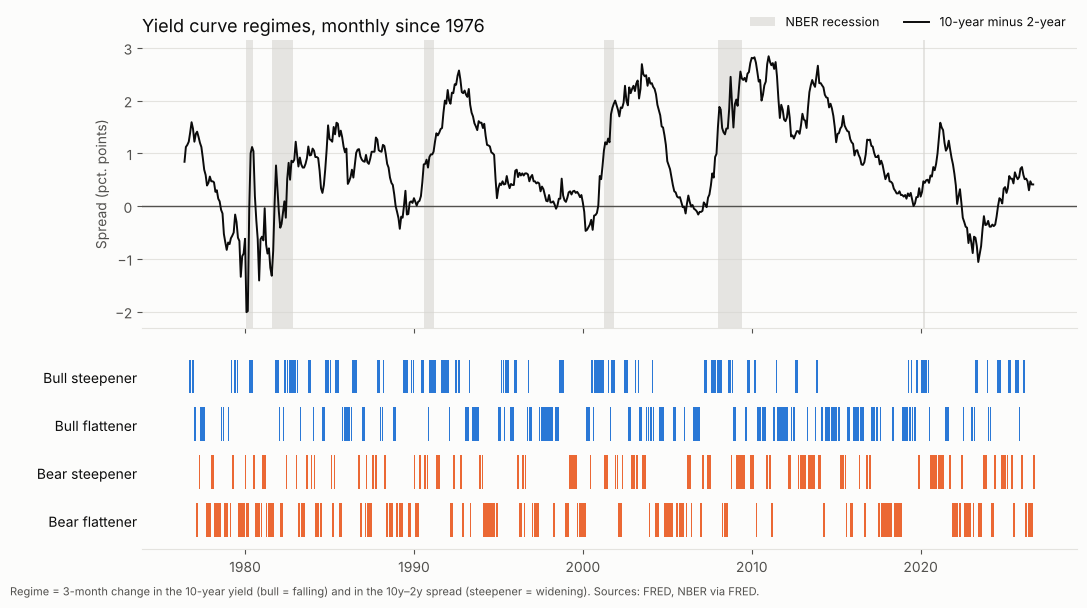

In [7]:
INK, MUTED, GRID, BG = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, RECESSION = "#2a78d6", "#eb6834", "#d6d5d0"
LANES = ["Bull steepener", "Bull flattener", "Bear steepener", "Bear flattener"]   # top to bottom
LANE_COLOR = {"Bull steepener": BLUE, "Bull flattener": BLUE, "Bear steepener": ORANGE, "Bear flattener": ORANGE}

t = data.index.to_timestamp()
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, facecolor=BG,
                                  gridspec_kw={"height_ratios": [2, 1.4], "hspace": 0.08})
for ax in (top, bottom):
    ax.set_facecolor(BG)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(colors=MUTED)

lo, hi = data["spread_10y2y"].min() - 0.3, data["spread_10y2y"].max() + 0.3
top.fill_between(t, lo, hi, where=(data["recession"] == 1).to_numpy(), color=RECESSION, alpha=0.6,
                 linewidth=0, step="mid", label="NBER recession")
top.axhline(0, color=MUTED, linewidth=1)
top.plot(t, data["spread_10y2y"], color=INK, linewidth=1.4, label="10-year minus 2-year")
top.set_ylim(lo, hi)
top.set_ylabel("Spread (pct. points)", color=MUTED)
top.grid(axis="y", color=GRID, linewidth=0.8)
top.set_axisbelow(True)
top.legend(loc="lower right", bbox_to_anchor=(1, 1.0), frameon=False, ncol=2, fontsize=9, labelcolor=INK)
top.set_title("Yield curve regimes, monthly since 1976", loc="left", color=INK, fontsize=13)

for i, name in enumerate(LANES):
    months = data.index[data["regime"] == name].to_timestamp()
    y = len(LANES) - 1 - i
    bottom.bar(months, 0.7, width=28, bottom=y - 0.35, align="edge", color=LANE_COLOR[name], linewidth=0)
bottom.set_yticks(range(len(LANES)))
bottom.set_yticklabels(list(reversed(LANES)), color=INK)
bottom.set_ylim(-0.6, len(LANES) - 0.4)
bottom.tick_params(axis="y", length=0)

fig.text(0.01, 0.005, "Regime = 3-month change in the 10-year yield (bull = falling) and in the 10y–2y spread "
         "(steepener = widening). Sources: FRED, NBER via FRED.", color=MUTED, fontsize=8)
fig.subplots_adjust(left=0.13, right=0.98, top=0.9, bottom=0.08)
fig.savefig(FIGS / "regime_timeline.png", dpi=200, facecolor=BG)
plt.show()

### 8. Save the labeled dataset
This writes `data/monthly_with_regimes.csv`: your Week 1 dataset plus four new columns, `chg_10y`, `chg_2y`, `chg_slope` and `regime`. In Colab, the next cell also downloads it and the chart to your computer. Upload both to your GitHub repository.

In [8]:
data.round(4).to_csv(DATA / "monthly_with_regimes.csv")
print("Saved", DATA / "monthly_with_regimes.csv", "-", len(data), "rows x", data.shape[1] + 1, "columns")

try:                                   # only works inside Google Colab
    from google.colab import files
    files.download(str(DATA / "monthly_with_regimes.csv"))
    files.download(str(FIGS / "regime_timeline.png"))
except ImportError:
    print("Not running in Colab: find the files in the data/ and figures/ folders.")

Saved data/monthly_with_regimes.csv - 604 rows x 26 columns
Not running in Colab: find the files in the data/ and figures/ folders.


### 9. Week 3 study questions
1. The label for March 2008 uses only the March 2008 and December 2007 values. Why does that protect you from look-ahead bias?
2. Regimes switch about 4–5 times a year and last under 3 months on average. What does that say about how noisy a 3-month window is, and what could you try in Week 6 to make the labels steadier?
3. On the timeline chart, which regime shows up most during 2022? During late 2007–2008? Does that match what you wrote in Week 2?
4. Why did the notebook drop the October 2026 row, and what would go wrong if it hadn’t?

**Next (Week 4):** pair each month’s label with the **next** month’s sector returns. That’s how you test your Week 2 hypotheses without cheating.